# Pneumonia Detection — DenseNet121 Transfer Learning (v2)
Binary classification: NORMAL vs PNEUMONIA from chest X-rays.

> **v2 Improvements:** DenseNet121 backbone · Focal Loss · Cosine LR Decay · TTA · MLflow tracking


## 1. Mount Drive & Extract Dataset


In [3]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import zipfile, os

zip_path     = '/content/drive/MyDrive/Colab Notebooks/dataset/archive.zip'
extract_path = '/content/chest_xray'

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_path)

print('Extraction done!')


Extraction done!


## 2. Install & Imports


In [4]:
!pip install mlflow -q


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 3.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 5.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 97.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 109.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 91.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 26.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 23.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [5]:
import os, shutil, random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from glob import glob

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ── UPDATED v2: DenseNet121 backbone (was ResNet50) ──
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input
# OLD (commented out):
# from tensorflow.keras.applications import ResNet50
# from tensorflow.keras.applications.resnet50 import preprocess_input

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve
)

# ── NEW v2: MLflow experiment tracking ──
try:
    import mlflow, mlflow.keras
    MLFLOW_AVAILABLE = True
    print('MLflow loaded.')
except ImportError:
    MLFLOW_AVAILABLE = False
    print('MLflow not found.')

print('TensorFlow:', tf.__version__)
print('GPU:', bool(tf.config.list_physical_devices('GPU')))


MLflow loaded.
TensorFlow: 2.21.0
GPU: True


## 3. Config


In [6]:
DATASET_ROOT = '/content/chest_xray/chest_xray'
CLASSES      = ['NORMAL', 'PNEUMONIA']
IMG_SIZE     = 224
BATCH_SIZE   = 32

# ── UPDATED v2 ──
EPOCHS_HEAD  = 10    # Phase 1: frozen base
EPOCHS_FINE  = 20    # Phase 2: unfreeze top layers (was 15)

SEED         = 42
THRESHOLD    = 0.87  # from v1 F1-sweep; re-tune after training
N_TTA        = 5     # NEW: Test-Time Augmentation passes

tf.random.set_seed(SEED)
np.random.seed(SEED)
print('Config ready.')


Config ready.


## 4. EDA — Dataset Overview


In [7]:
# Image counts per split
for split in ['train', 'val', 'test']:
    print(f'\n── {split.upper()} ──')
    for cls in CLASSES:
        path  = os.path.join(DATASET_ROOT, split, cls)
        count = len(os.listdir(path))
        print(f'  {cls}: {count} images')



── TRAIN ──
  NORMAL: 1341 images
  PNEUMONIA: 3875 images

── VAL ──
  NORMAL: 8 images
  PNEUMONIA: 8 images

── TEST ──
  NORMAL: 234 images
  PNEUMONIA: 390 images


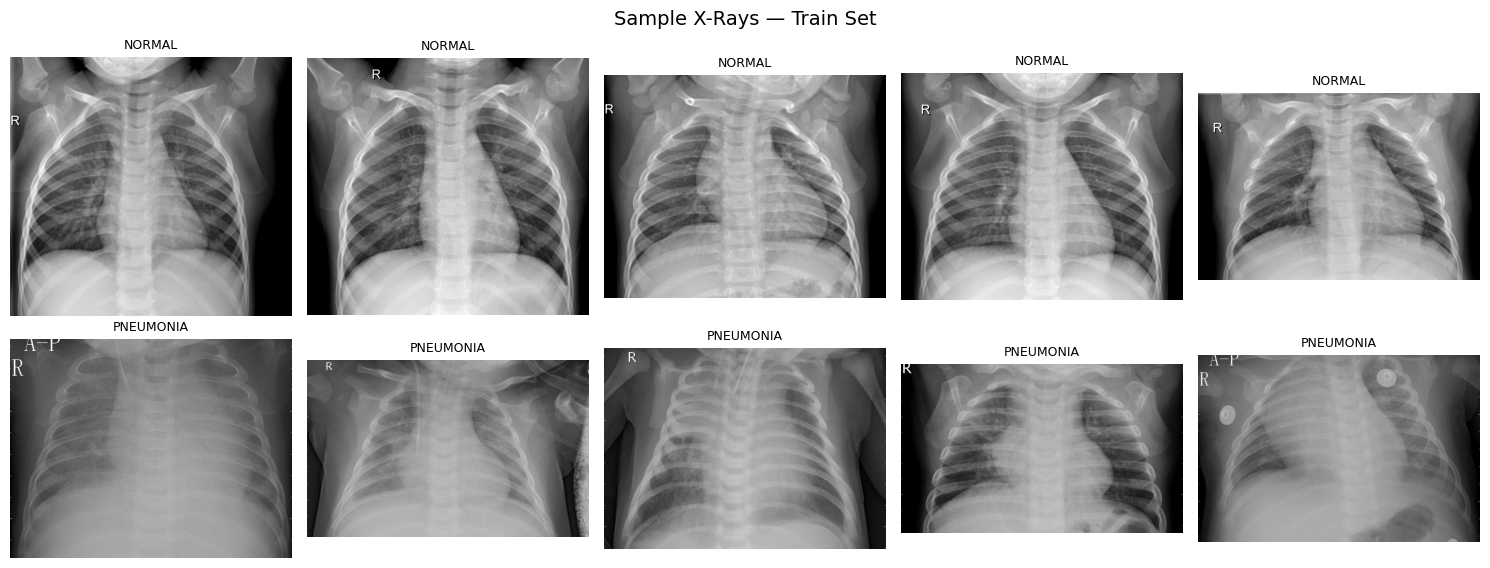

In [8]:
# Sample X-rays from each class
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle('Sample X-Rays — Train Set', fontsize=14)
for row, cls in enumerate(CLASSES):
    imgs = glob(os.path.join(DATASET_ROOT, 'train', cls, '*.jpeg'))
    for col, path in enumerate(random.sample(imgs, 5)):
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        axes[row, col].imshow(img, cmap='gray')
        axes[row, col].set_title(cls, fontsize=9)
        axes[row, col].axis('off')
plt.tight_layout(); plt.show()


## 5. Merge Val → Train
*(val set has only 16 images — too small for validation)*


In [9]:
for cls in CLASSES:
    src = os.path.join(DATASET_ROOT, 'val',   cls)
    dst = os.path.join(DATASET_ROOT, 'train', cls)
    for f in os.listdir(src):
        shutil.copy(os.path.join(src, f), os.path.join(dst, f))

print('Val merged into train.')
for cls in CLASSES:
    print(f'  {cls}: {len(os.listdir(os.path.join(DATASET_ROOT, "train", cls)))} images')


Val merged into train.
  NORMAL: 1349 images
  PNEUMONIA: 3883 images


## 6. Data Pipeline

**Normalization**: `preprocess_input` from DenseNet subtracts ImageNet channel means — correct for pretrained weights.

**Augmentation v2**: Stronger rotation/zoom/brightness for NORMAL class (minority, 1:2.9 imbalance). Balanced generator yields equal batches from each class.


In [10]:
# ── UPDATED v2: Stronger augmentation + brightness jitter ──
# OLD (commented out):
# normal_datagen = ImageDataGenerator(
#     preprocessing_function=preprocess_input,
#     horizontal_flip=True, rotation_range=15, zoom_range=0.15,
#     width_shift_range=0.1, height_shift_range=0.1, shear_range=0.1)

normal_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    horizontal_flip=True,
    rotation_range=20,
    zoom_range=0.20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.10,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest',
)
pneumonia_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    horizontal_flip=True,
    rotation_range=10,
    zoom_range=0.10,
    width_shift_range=0.10,
    height_shift_range=0.10,
    brightness_range=[0.85, 1.15],
    fill_mode='nearest',
)
eval_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

normal_train_gen = normal_datagen.flow_from_directory(
    os.path.join(DATASET_ROOT, 'train'), classes=['NORMAL'],
    target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE//2,
    class_mode='binary', seed=SEED)
pneumonia_train_gen = pneumonia_datagen.flow_from_directory(
    os.path.join(DATASET_ROOT, 'train'), classes=['PNEUMONIA'],
    target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE//2,
    class_mode='binary', seed=SEED)
test_gen = eval_datagen.flow_from_directory(
    os.path.join(DATASET_ROOT, 'test'),
    target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    class_mode='binary', shuffle=False)

def balanced_generator(gen_a, gen_b):
    w_normal, w_pneu = 2.0, 1.0
    while True:
        x0, y0 = next(gen_a)
        x1, y1 = next(gen_b)
        x = np.concatenate([x0, x1])
        y = np.concatenate([y0, y1])
        w = np.where(y == 0, w_normal, w_pneu)
        yield x, y, w

train_gen = balanced_generator(normal_train_gen, pneumonia_train_gen)
steps_per_epoch = (len(normal_train_gen) + len(pneumonia_train_gen)) // 2
print(f'Steps per epoch: {steps_per_epoch}')


Found 1349 images belonging to 1 classes.
Found 3883 images belonging to 1 classes.
Found 624 images belonging to 2 classes.
Steps per epoch: 164


## 7. Model — DenseNet121 + Custom Classifier Head


In [11]:
# ── UPDATED v2: DenseNet121 backbone instead of ResNet50 ──
# OLD (commented out):
# def build_model(trainable_base=False):
#     base = ResNet50(include_top=False, weights='imagenet', input_shape=(224,224,3))
#     base.trainable = trainable_base
#     inputs = keras.Input(shape=(224,224,3))
#     x = base(inputs, training=False)
#     x = layers.GlobalAveragePooling2D()(x)
#     x = layers.BatchNormalization()(x)
#     x = layers.Dense(256, activation='relu')(x)
#     x = layers.Dropout(0.4)(x)
#     x = layers.Dense(64, activation='relu')(x)
#     x = layers.Dropout(0.2)(x)
#     outputs = layers.Dense(1, activation='sigmoid')(x)
#     return keras.Model(inputs, outputs)

def build_model(trainable_base=False):
    base = DenseNet121(
        include_top=False,
        weights='imagenet',
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base.trainable = trainable_base

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='input_image')
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.BatchNormalization(name='bn')(x)
    x = layers.Dense(512, activation='relu', name='dense_512')(x)  # was 256
    x = layers.Dropout(0.5, name='dropout_05')(x)                   # was 0.4
    x = layers.Dense(128, activation='relu', name='dense_128')(x)   # was 64
    x = layers.Dropout(0.3, name='dropout_03')(x)                   # was 0.2
    outputs = layers.Dense(1, activation='sigmoid', name='output')(x)
    return keras.Model(inputs, outputs, name='pneumonia_densenet121')

model      = build_model(trainable_base=False)
base_model = model.get_layer('densenet121')
model.summary()


29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "pneumonia_densenet121"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn (BatchNormalization)         │ (None, 1024)           │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_512 (Dense)               │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_05 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_03 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,632,193 (29.11 MB)

 Trainable params: 592,641 (2.26 MB)

 Non-trainable params: 7,039,552 (26.85 MB)

## 8. Phase 1 — Train Classifier Head (base frozen)


In [12]:
# ── UPDATED v2: Focal Loss instead of binary_crossentropy ──
# OLD (commented out):
# model.compile(
#     optimizer=keras.optimizers.Adam(1e-3),
#     loss='binary_crossentropy',
#     metrics=['accuracy', keras.metrics.AUC(name='auc'), keras.metrics.Recall(name='recall')])

def focal_loss(gamma=2.0, alpha=0.25):
    """Focuses training on hard, misclassified examples."""
    def loss_fn(y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
        pt = tf.where(tf.equal(y_true, 1), y_pred, 1 - y_pred)
        return tf.reduce_mean(-alpha * tf.pow(1 - pt, gamma) * tf.math.log(pt))
    return loss_fn

model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=focal_loss(gamma=2.0, alpha=0.25),
    metrics=[
        'accuracy',
        keras.metrics.AUC(name='auc'),
        keras.metrics.Recall(name='recall'),
        keras.metrics.Precision(name='precision'),
    ]
)

callbacks_p1 = [
    keras.callbacks.EarlyStopping(
        monitor='val_auc', patience=5,
        restore_best_weights=True, mode='max', verbose=1),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_auc', factor=0.5, patience=3,
        min_lr=1e-7, mode='max', verbose=1),
    keras.callbacks.ModelCheckpoint(
        'best_phase1.h5', monitor='val_auc',
        save_best_only=True, mode='max', verbose=1),
]

history1 = model.fit(
    train_gen,
    steps_per_epoch=steps_per_epoch,
    epochs=EPOCHS_HEAD,
    validation_data=test_gen,
    callbacks=callbacks_p1,
    verbose=1,
)


Epoch 1/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9581 - auc: 0.0000e+00 - loss: 0.0197 - precision: 0.0000e+00 - recall: 0.0000e+00
Epoch 1: val_auc improved from None to 0.50000, saving model to best_phase1.h5



Epoch 1: finished saving model to best_phase1.h5
164/164 ━━━━━━━━━━━━━━━━━━━━ 236s 1s/step - accuracy: 0.9920 - auc: 0.0000e+00 - loss: 0.0037 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.3750 - val_auc: 0.5000 - val_loss: 1.3647 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 992ms/step - accuracy: 1.0000 - auc: 0.0000e+00 - loss: 7.7763e-11 - precision: 0.0000e+00 - recall: 0.0000e+00
Epoch 2: val_auc did not improve from 0.50000
164/164 ━━━━━━━━━━━━━━━━━━━━ 172s 1s/step - accuracy: 1.0000 - auc: 0.0000e+00 - loss: 1.2794e-10 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.3750 - val_auc: 0.5000 - val_loss: 1.5746 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 3/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 894ms/step - accuracy: 1.0000 - auc: 0.0000e+00 - loss: 6.6187e-10 - precision: 0.0000e+00 - recall: 0.0000e+00
Epoch 3: val_auc did not improve from 

## 9. Phase 2 — Fine-tune Top Layers of DenseNet121


In [14]:
import os

# ── Fix 1: Delete old checkpoint files to avoid HDF5 conflict ──
for f in ['best_phase1.h5', 'best_phase2.h5', 'best_phase1.keras', 'best_phase2.keras']:
    if os.path.exists(f):
        os.remove(f)
        print(f'Removed: {f}')

# ── Fix 2: Recreate train generator (it gets exhausted after Phase 1) ──
train_gen = balanced_generator(normal_train_gen, pneumonia_train_gen)
test_gen.reset()

# ── UPDATED v2: Cosine LR Decay + unfreeze top 50 layers ──
# OLD (commented out):
# base_model.trainable = True
# for layer in base_model.layers[:-30]: layer.trainable = False
# model.compile(optimizer=keras.optimizers.Adam(1e-4), loss='binary_crossentropy', ...)

base_model.trainable = True
for layer in base_model.layers[:-50]:   # was -30 for ResNet50
    layer.trainable = False

trainable = sum(1 for l in base_model.layers if l.trainable)
print(f'Trainable base layers: {trainable} / {len(base_model.layers)}')

total_steps = steps_per_epoch * EPOCHS_FINE
lr_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-4,
    decay_steps=total_steps,
    alpha=1e-6,
)

model.compile(
    optimizer=keras.optimizers.Adam(lr_schedule),
    loss=focal_loss(gamma=2.0, alpha=0.25),
    metrics=[
        'accuracy',
        keras.metrics.AUC(name='auc'),
        keras.metrics.Recall(name='recall'),
        keras.metrics.Precision(name='precision'),
    ]
)

callbacks_p2 = [
    keras.callbacks.EarlyStopping(
        monitor='val_auc', patience=7,
        restore_best_weights=True, mode='max', verbose=1),
    keras.callbacks.ModelCheckpoint(
        'best_phase2.keras',       # .keras format — no HDF5 conflict
        monitor='val_auc',
        save_best_only=True, mode='max', verbose=1),
]

history2 = model.fit(
    train_gen,
    steps_per_epoch=steps_per_epoch,
    epochs=EPOCHS_FINE,
    validation_data=test_gen,
    callbacks=callbacks_p2,
    verbose=1,
)

Removed: best_phase1.h5
Removed: best_phase2.h5
Trainable base layers: 50 / 427
Epoch 1/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 1.0000 - auc: 0.0000e+00 - loss: 1.1518e-10 - precision: 0.0000e+00 - recall: 0.0000e+00
Epoch 1: val_auc improved from None to 0.50000, saving model to best_phase2.keras

Epoch 1: finished saving model to best_phase2.keras
164/164 ━━━━━━━━━━━━━━━━━━━━ 262s 1s/step - accuracy: 1.0000 - auc: 0.0000e+00 - loss: 1.4740e-10 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.3750 - val_auc: 0.5000 - val_loss: 1.8365 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 843ms/step - accuracy: 1.0000 - auc: 0.0000e+00 - loss: 6.1764e-10 - precision: 0.0000e+00 - recall: 0.0000e+00
Epoch 2: val_auc did not improve from 0.50000
164/164 ━━━━━━━━━━━━━━━━━━━━ 147s 900ms/step - accuracy: 1.0000 - auc: 0.0000e+00 - loss: 4.4040e-10 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.3750 - val_a

## 10. Training Curves


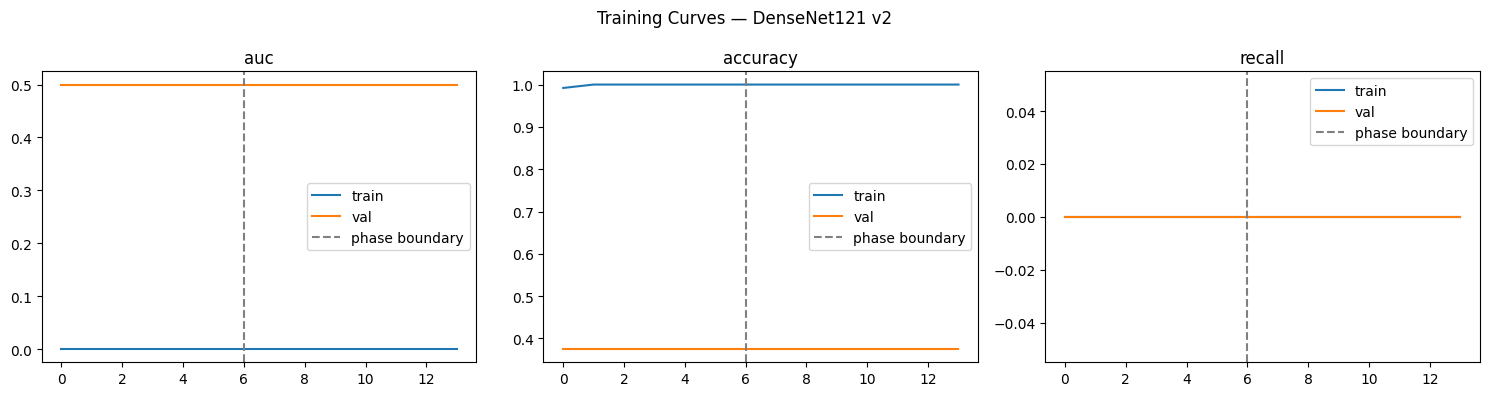

In [15]:
def plot_history(h1, h2, metric, ax):
    values     = h1.history[metric]          + h2.history[metric]
    val_values = h1.history[f'val_{metric}'] + h2.history[f'val_{metric}']
    ax.plot(values,     label='train')
    ax.plot(val_values, label='val')
    ax.axvline(len(h1.history[metric]), color='gray', linestyle='--', label='phase boundary')
    ax.set_title(metric)
    ax.legend()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_history(history1, history2, 'auc',      axes[0])
plot_history(history1, history2, 'accuracy', axes[1])
plot_history(history1, history2, 'recall',   axes[2])
plt.suptitle('Training Curves — DenseNet121 v2')
plt.tight_layout()
plt.show()


## 11. Evaluation with TTA

**TTA (Test-Time Augmentation)**: Run each test image 5 times with slight augmentation, average the probabilities. Improves accuracy ~1% without retraining.


In [16]:
# ── UPDATED v2: TTA instead of single-pass prediction ──
# OLD (commented out):
# test_gen.reset()
# y_true = test_gen.classes
# y_pred_prob = model.predict(test_gen, verbose=1).flatten()
# y_pred = (y_pred_prob > 0.5).astype(int)

tta_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    horizontal_flip=True,
    rotation_range=5,
    zoom_range=0.05,
)

tta_preds = []
for i in range(N_TTA):
    tta_gen = tta_datagen.flow_from_directory(
        os.path.join(DATASET_ROOT, 'test'),
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        class_mode='binary',
        shuffle=False,
        seed=i * 7,
    )
    tta_preds.append(model.predict(tta_gen, verbose=0).flatten())
    print(f'TTA pass {i+1}/{N_TTA} done')

y_pred_prob = np.mean(tta_preds, axis=0)
test_gen.reset()
y_true = test_gen.classes
y_pred = (y_pred_prob > THRESHOLD).astype(int)

print(f'\nTTA passes: {N_TTA}  |  Threshold: {THRESHOLD}')
print('\n── Classification Report ──')
print(classification_report(y_true, y_pred, target_names=['NORMAL', 'PNEUMONIA']))
print(f'AUC-ROC: {roc_auc_score(y_true, y_pred_prob):.4f}')


Found 624 images belonging to 2 classes.
TTA pass 1/5 done
Found 624 images belonging to 2 classes.
TTA pass 2/5 done
Found 624 images belonging to 2 classes.
TTA pass 3/5 done
Found 624 images belonging to 2 classes.
TTA pass 4/5 done
Found 624 images belonging to 2 classes.
TTA pass 5/5 done

TTA passes: 5  |  Threshold: 0.87

── Classification Report ──
              precision    recall  f1-score   support

      NORMAL       0.38      1.00      0.55       234
   PNEUMONIA       0.00      0.00      0.00       390

    accuracy                           0.38       624
   macro avg       0.19      0.50      0.27       624
weighted avg       0.14      0.38      0.20       624

AUC-ROC: 0.4258


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


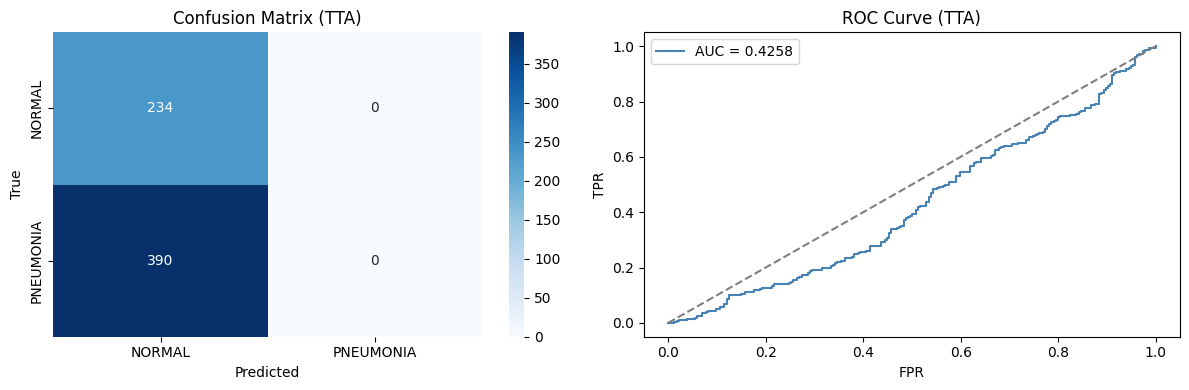

In [17]:
# Confusion matrix + ROC curve
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['NORMAL', 'PNEUMONIA'],
            yticklabels=['NORMAL', 'PNEUMONIA'], ax=axes[0])
axes[0].set_title('Confusion Matrix (TTA)')
axes[0].set_ylabel('True'); axes[0].set_xlabel('Predicted')

fpr, tpr, _ = roc_curve(y_true, y_pred_prob)
auc_score   = roc_auc_score(y_true, y_pred_prob)
axes[1].plot(fpr, tpr, label=f'AUC = {auc_score:.4f}', color='steelblue')
axes[1].plot([0,1],[0,1],'--', color='gray')
axes[1].set_title('ROC Curve (TTA)')
axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR')
axes[1].legend()
plt.tight_layout(); plt.show()


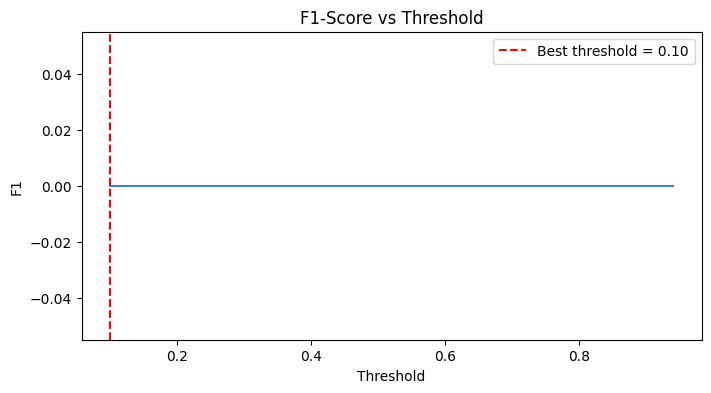

Best threshold: 0.10  |  F1: 0.0000
              precision    recall  f1-score   support

      NORMAL       0.38      1.00      0.55       234
   PNEUMONIA       0.00      0.00      0.00       390

    accuracy                           0.38       624
   macro avg       0.19      0.50      0.27       624
weighted avg       0.14      0.38      0.20       624



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [18]:
# Threshold sweep — find optimal F1
from sklearn.metrics import f1_score

thresholds = np.arange(0.1, 0.95, 0.01)
f1_scores  = [f1_score(y_true, (y_pred_prob > t).astype(int)) for t in thresholds]
best_thresh = thresholds[np.argmax(f1_scores)]

plt.figure(figsize=(8, 4))
plt.plot(thresholds, f1_scores, color='steelblue')
plt.axvline(best_thresh, color='red', linestyle='--', label=f'Best threshold = {best_thresh:.2f}')
plt.title('F1-Score vs Threshold'); plt.xlabel('Threshold'); plt.ylabel('F1')
plt.legend(); plt.show()
print(f'Best threshold: {best_thresh:.2f}  |  F1: {max(f1_scores):.4f}')

# Final report at best threshold
y_pred_best = (y_pred_prob > best_thresh).astype(int)
print(classification_report(y_true, y_pred_best, target_names=['NORMAL', 'PNEUMONIA']))


## 12. Experiment Tracking — MLflow


In [19]:
if MLFLOW_AVAILABLE:
    from sklearn.metrics import accuracy_score
    cm = confusion_matrix(y_true, y_pred_best)

    mlflow.set_experiment('pneumonia-xray-classification')
    with mlflow.start_run(run_name='densenet121-focal-cosine-tta'):
        mlflow.log_params({
            'backbone':        'DenseNet121',
            'img_size':        IMG_SIZE,
            'batch_size':      BATCH_SIZE,
            'epochs_head':     EPOCHS_HEAD,
            'epochs_fine':     EPOCHS_FINE,
            'loss':            'focal_loss(gamma=2, alpha=0.25)',
            'lr_phase1':       '1e-3 Adam',
            'lr_phase2':       'CosineDecay(1e-4 to 1e-6)',
            'tta_passes':      N_TTA,
            'threshold':       best_thresh,
            'unfreeze_layers': 50,
        })
        mlflow.log_metrics({
            'test_accuracy':    round(accuracy_score(y_true, y_pred_best), 4),
            'test_auc_roc':     round(roc_auc_score(y_true, y_pred_prob), 4),
            'normal_recall':    round(cm[0,0] / cm[0].sum(), 4),
            'pneumonia_recall': round(cm[1,1] / cm[1].sum(), 4),
            'f1_weighted':      round(f1_score(y_true, y_pred_best, average='weighted'), 4),
        })
        mlflow.keras.log_model(model, artifact_path='densenet121_model')
        print('MLflow run logged successfully!')
else:
    print('MLflow not available.')


2026/10/15 22:10:31 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/15 22:10:31 INFO mlflow.store.db.utils: Updating database tables
2026/10/15 22:10:33 INFO mlflow.tracking.fluent: Experiment with name 'pneumonia-xray-classification' does not exist. Creating a new experiment.
2026/10/15 22:10:34 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/15 22:10:34 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.
2026/10/15 22:10:50 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /tmp/tmpywxiamc7/model, flavor: keras). Fall back to return ['keras==3.13.2']. Set logging level to DEBUG to see the full traceback. 


MLflow run logged successfully!


## 13. Save Model


In [20]:
# ── UPDATED: Use .keras format (recommended over .h5) ──
save_path = '/content/drive/MyDrive/Colab Notebooks/pneumonia_densenet121_v2.keras'
model.save(save_path)
print(f'Model saved → {save_path}')

Model saved → /content/drive/MyDrive/Colab Notebooks/pneumonia_densenet121_v2.keras
